# OBJETIVO 1

Simular la amortización de préstamos bajo diferentes sistemas, 
concretamente francés y alemán, eligiendo el método con el que se va a continuar 
el proceso

# Amortización de préstamos: sistema francés vs alemán

In [18]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [19]:
datos= pd.read_excel("datos/datos_limpio_automovil.xlsx")

In [20]:
#cambiamos el nombre de las columnas para que coincidan con una terminología mas financiera.
datos = datos.rename(columns={
    "Monto_Inicial": "capital_prestado",
    "Ratio_Interes": "interes_anual",
    "Duracion": "num_meses"
})

In [21]:
#comprobamos que se han cambiado bien 
datos.columns

Index(['Unnamed: 0', 'ID', 'Edad', 'Ingresos', 'capital_prestado',
       'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'interes_anual',
       'num_meses', 'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca',
       'Personas_Cargo', 'Fiador', 'Impago', 'Prima', 'Estudios_Doctorado',
       'Estudios_Escolar', 'Estudios_Grado Universitario', 'Estudios_Máster',
       'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'Estado_Civil_Casado',
       'Estado_Civil_Divorciado', 'Estado_Civil_Soltero'],
      dtype='str')

In [22]:
#creamos un df con estas columnas ID, capital_prestado, interes_anual, num_meses, Ingresos, Ratio_Deuda_Ingresos, Impago
datos_1= datos.copy()
datos_fr= datos_1[["ID", "capital_prestado", "interes_anual", "num_meses", "Ingresos", "Ratio_Deuda_Ingresos", "Impago"]]
datos_aleman= datos_1[["ID", "capital_prestado", "interes_anual", "num_meses", "Ingresos", "Ratio_Deuda_Ingresos", "Impago"]]

In [23]:
datos_fr.head()

,ID,capital_prestado,interes_anual,num_meses,Ingresos,Ratio_Deuda_Ingresos,Impago
0,O77MPJ,6973,19.05,36,19153,0.10,1
1,IYOL1S,40000,9.74,24,39531,0.19,0
2,FRMZVN,16448,14.73,24,40348,0.10,1
3,YKHXVY,42040,13.24,48,41732,0.18,1
4,NHDJTK,16406,9.74,36,35085,0.13,0


In [24]:
datos_aleman.head()

,ID,capital_prestado,interes_anual,num_meses,Ingresos,Ratio_Deuda_Ingresos,Impago
0,O77MPJ,6973,19.05,36,19153,0.10,1
1,IYOL1S,40000,9.74,24,39531,0.19,0
2,FRMZVN,16448,14.73,24,40348,0.10,1
3,YKHXVY,42040,13.24,48,41732,0.18,1
4,NHDJTK,16406,9.74,36,35085,0.13,0


In [25]:
datos_fr.shape

(76924, 7)

In [26]:
datos_aleman.shape

(76924, 7)

In [27]:
#Cuadros de amortización (para ver UN préstamo mes a mes)
def cuadro_frances(capital, interes_anual, meses):
    #convierte el interes anual en mensual
    i = interes_anual / 100 / 12
    cuota = capital / meses if i == 0 else capital * i / (1 - (1 + i) ** (-meses))
    saldo, filas = capital, []
    for k in range(1, meses + 1):
        interes = saldo * i
        amortizacion = cuota - interes
        saldo_final = saldo - amortizacion
        filas.append([k, saldo, cuota, interes, amortizacion, saldo_final])
        saldo = saldo_final
    out = pd.DataFrame(filas, columns=["mes", "saldo_inicial", "cuota",
                                       "interes", "amortizacion", "saldo_final"])
    out.loc[out.index[-1], "saldo_final"] = 0.0
    return out

In [28]:
def cuadro_aleman(capital, interes_anual, meses):
    i = interes_anual / 100 / 12
    amortizacion = capital / meses
    saldo, filas = capital, []
    for k in range(1, meses + 1):
        interes = saldo * i
        cuota = amortizacion + interes
        saldo_final = saldo - amortizacion
        filas.append([k, saldo, cuota, interes, amortizacion, saldo_final])
        saldo = saldo_final
    out = pd.DataFrame(filas, columns=["mes", "saldo_inicial", "cuota",
                                       "interes", "amortizacion", "saldo_final"])
    out.loc[out.index[-1], "saldo_final"] = 0.0
    return out

Diferencia entre los dos sistemas:
- **Francés :** la **cuota es constante**, C·i / (1 − (1+i)^−n). Como el interés baja cada mes, la amortización de capital va subiendo.
- **Alemán :** la **amortización de capital es constante**, C / n. La cuota es amortización + interés, y como el interés baja cada mes, la cuota va bajando.

   mes  saldo_inicial   cuota  interes  amortizacion  saldo_final
0    1        6973.00  255.78   110.70        145.08      6827.92
1    2        6827.92  255.78   108.39        147.39      6680.53
2    3        6680.53  255.78   106.05        149.73      6530.81
   mes  saldo_inicial   cuota  interes  amortizacion  saldo_final
0    1        6973.00  304.39   110.70        193.69      6779.31
1    2        6779.31  301.32   107.62        193.69      6585.61
2    3        6585.61  298.24   104.55        193.69      6391.92


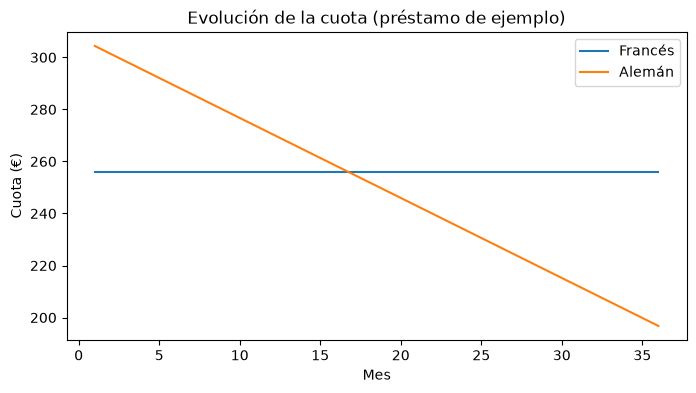

In [29]:
# Ejemplo con un préstamo (primer prestamo)
p_fr = datos_fr.iloc[0]
fr = cuadro_frances(p_fr["capital_prestado"], p_fr["interes_anual"], int(p_fr["num_meses"]))
p_aleman = datos_aleman.iloc[0]
aleman = cuadro_aleman(p_aleman["capital_prestado"], p_aleman["interes_anual"], int(p_aleman["num_meses"]))
print(fr.head(3).round(2))
print(aleman.head(3).round(2))

plt.figure(figsize=(8, 4))
plt.plot(fr["mes"], fr["cuota"], label="Francés")
plt.plot(aleman["mes"], aleman["cuota"], label="Alemán")
plt.xlabel("Mes"); plt.ylabel("Cuota (€)")
plt.title("Evolución de la cuota (préstamo de ejemplo)")
plt.legend(); plt.show()

Mediante este codigo se usa el primer préstamo (6.973 €, 19,05 %, 36 meses), y se genera su cuadro con cada sistema, muestra los 3 primeros meses y dibuja cómo evoluciona la cuota mes a mes.

- En el francés la cuota no cambia (255,78 €), y la amortización de capital crece (145,08 → 147,39 → 149,73) porque el interés baja.
- En el alemán la amortización es siempre la misma (193,69 € = 6.973 / 36) y la cuota baja unos 3,07 € cada mes.
- El interés del primer mes es el mismo en los dos (110,70 € = 6.973 × 0,015875), porque ambos parten de la misma deuda.

Gráfico: la línea del francés es plana (255,78 €) y la del alemán desciende de 304,39 € a unos 197 € en el último mes. Se cruzan alrededor del mes 17( antes de ese mes el alemán es más caro de pagar y después es más barato) Es la visualización de la idea clave de la comparación: el alemán exige más esfuerzo al principio y menos al final.

In [30]:
# Sistema FRANCÉS para todos los préstamos
i_f = datos_fr["interes_anual"] / 100 / 12
C_f = datos_fr["capital_prestado"]
n_f = datos_fr["num_meses"].astype(int)

with np.errstate(divide="ignore", invalid="ignore"):
    cuota_fr = np.where(i_f == 0, C_f / n_f, C_f * i_f / (1 - (1 + i_f) ** (-n_f)))

datos_fr["cuota"] = cuota_fr                       # cuota constante
datos_fr["interes_total"] = cuota_fr * n_f - C_f
datos_fr["total_pagado"] = cuota_fr * n_f

- i_f, C_f, n_f: columnas con el interés mensual, el capital y el número de meses de cada préstamo.
- cuota_fr: aplica la fórmula de la cuota francesa a todos los préstamos. Si algún préstamo tuviera interés 0, la fórmula daría 0/0, así que en ese caso se usa C / n
- Se añaden tres columnas:
  - cuota: cuota mensual constante
  - interes_total:cuota × n − capital, es decir, lo que se paga de más sobre el capital
  - total_pagado: cuota × n

In [31]:
datos_fr

,ID,capital_prestado,interes_anual,num_meses,Ingresos,Ratio_Deuda_Ingresos,Impago,cuota,interes_total,total_pagado
0,O77MPJ,6973,19.05,36,19153,0.10,1,255.778738,2235.034579,9208.034579
1,IYOL1S,40000,9.74,24,39531,0.19,0,1841.000634,4184.015211,44184.015211
2,FRMZVN,16448,14.73,24,40348,0.10,1,795.400039,2641.600945,19089.600945
3,YKHXVY,42040,13.24,48,41732,0.18,1,1132.842089,12336.420285,54376.420285
4,NHDJTK,16406,9.74,36,35085,0.13,0,527.375078,2579.502794,18985.502794
...,...,...,...,...,...,...,...,...,...,...
76919,9DP3XV,40252,12.74,36,45006,0.55,0,1351.213601,8391.689647,48643.689647
76920,R30LLT,15509,8.00,24,44124,0.17,0,701.430063,1325.321517,16834.321517
76921,W2Y3KE,331820,6.90,60,84570,0.55,0,6554.789657,61467.379439,393287.379439
76922,WVJ9ZC,19371,8.55,12,61642,0.10,0,1689.982924,908.795088,20279.795088


In [32]:
#si queresmos hacer el cuadro de otro prestamo
fila = datos_fr.iloc[1]   
cuadro_frances(fila["capital_prestado"], fila["interes_anual"], int(fila["num_meses"])).round(2) # 0 es el primero, 1 el segundo...

,mes,saldo_inicial,cuota,interes,amortizacion,saldo_final
0,1,40000.00,1841.0,324.67,1516.33,38483.67
1,2,38483.67,1841.0,312.36,1528.64,36955.02
2,3,36955.02,1841.0,299.95,1541.05,35413.98
3,4,35413.98,1841.0,287.44,1553.56,33860.42
4,5,33860.42,1841.0,274.83,1566.17,32294.25
5,6,32294.25,1841.0,262.12,1578.88,30715.37
6,7,30715.37,1841.0,249.31,1591.69,29123.68
7,8,29123.68,1841.0,236.39,1604.61,27519.06
8,9,27519.06,1841.0,223.36,1617.64,25901.43
9,10,25901.43,1841.0,210.23,1630.77,24270.66


In [33]:
# Sistema ALEMÁN para todos los préstamos
i_a = datos_aleman["interes_anual"] / 100 / 12
C_a = datos_aleman["capital_prestado"]
n_a = datos_aleman["num_meses"].astype(int)

datos_aleman["amortizacion_mensual"] = C_a / n_a      # capital constante
datos_aleman["cuota_inicial"] = C_a / n_a + C_a * i_a
datos_aleman["cuota_final"] = C_a / n_a + (C_a / n_a) * i_a
datos_aleman["interes_total"] = i_a * C_a * (n_a + 1) / 2
datos_aleman["total_pagado"] = C_a + datos_aleman["interes_total"]

A_a = C_a / n_a    #amortizacion constante
# intereses totales: suma del interés de cada mes, I_k = (C - k·A)·i
datos_aleman["interes_total"] = sum(
    np.where(k < n_a, (C_a - k * A_a) * i_a, 0) for k in range(int(n_a.max()))
)
datos_aleman["total_pagado"] = C_a + datos_aleman["interes_total"]

Se añaden cinco columnas:

- amortizacion_mensual = C / n: capital que se devuelve cada mes (constante).
- cuota_inicial = C/n + C·i: la primera cuota, la más alta (amortización más el interés sobre todo el capital).
- cuota_final = C/n + (C/n)·i: la última cuota, la más baja (el interés se calcula sobre el último trozo de capital, C/n).
- interes_total = i·C·(n+1)/2: intereses totales. Sale de que el saldo baja en línea recta, así que los intereses de cada mes forman una progresión aritmética cuya suma es esa expresión.
- total_pagado = C + interes_total.

In [34]:
# Validación contra el cuadro completo 
print("Cuota francesa :", round(datos_fr["cuota"].iloc[0], 4), round(fr["cuota"].iloc[0], 4))
print("Intereses fr.  :", round(datos_fr["interes_total"].iloc[0], 4), round(fr["interes"].sum(), 4))
print("Cuota inicial alemán:", round(datos_aleman["cuota_inicial"].iloc[0], 4), round(aleman["cuota"].iloc[0], 4))
print("Intereses alemán  :", round(datos_aleman["interes_total"].iloc[0], 4), round(aleman["interes"].sum(), 4))

Cuota francesa : 255.7787 255.7787
Intereses fr.  : 2235.0346 2235.0346
Cuota inicial alemán: 304.3908 304.3908
Intereses alemán  : 2047.8829 2047.8829


comprueba que las fórmulas aplicadas a toda la cartera dan el mismo resultado que el cuadro de amortización mes a mes del primer préstamo. Cada línea imprime dos números: el primero sale de la fórmula y el segundo del cuadro.

Los cuatro pares coinciden (cuota francesa 255,7787; cuota inicial alemana 304,3908; intereses 2.235,0346 en el francés y 2.047,8829 en el alemán), así que las fórmulas son correctas. Además se ve la diferencia entre sistemas en este préstamo: el alemán paga 187,15 € menos de intereses (2.235,03 − 2.047,88).

In [35]:
# Comparación para ELEGIR el método usando toda la cartera
# Carga inicial = primera cuota / ingreso mensual (se asume Ingresos ANUALES)
datos_fr["carga_inicial"] = datos_fr["cuota"] / (datos_fr["Ingresos"] / 12)
datos_aleman["carga_inicial"] = datos_aleman["cuota_inicial"] / (datos_aleman["Ingresos"] / 12)

comparativa = pd.DataFrame({
    "Francés": [datos_fr["cuota"].mean(), datos_fr["interes_total"].mean(),
                datos_fr["carga_inicial"].median()],
    "Alemán": [datos_aleman["cuota_inicial"].mean(), datos_aleman["interes_total"].mean(),
               datos_aleman["carga_inicial"].median()],
}, index=["Cuota inicial media (€)", "Intereses totales medios (€)",
          "Carga inicial mediana s/ ingresos"])
print(comparativa.round(3))

ahorro_aleman = datos_fr["interes_total"] - datos_aleman["interes_total"]
print("\nAhorro medio en intereses con alemán (€):", round(ahorro_aleman.mean(), 2))
print("Préstamos con cuota inicial > 30% del ingreso mensual:",
      f"alemán {(datos_aleman['carga_inicial'] > 0.30).mean():.1%} | "
      f"francés {(datos_fr['carga_inicial'] > 0.30).mean():.1%}")

print("\nCarga inicial mediana (francés) según Impago:")
print(datos_fr.groupby("Impago")["carga_inicial"].median().round(3))

                                    Francés    Alemán
Cuota inicial media (€)            1690.459  1870.246
Intereses totales medios (€)       8135.839  7612.815
Carga inicial mediana s/ ingresos     0.314     0.353

Ahorro medio en intereses con alemán (€): 523.02
Préstamos con cuota inicial > 30% del ingreso mensual: alemán 56.3% | francés 51.8%

Carga inicial mediana (francés) según Impago:
Impago
0    0.315
1    0.300
Name: carga_inicial, dtype: float64


usando toda la cartera (no solo el primer préstamo).

1. carga_inicial = primera cuota / ingreso mensual (Ingresos / 12, suponiendo que Ingresos es anual). Indica qué parte del ingreso mensual consume la primera cuota.
2. comparativa: tabla con la cuota inicial media, los intereses totales medios y la carga inicial mediana de cada sistema.
3. ahorro_aleman: para cada préstamo, intereses del francés menos intereses del alemán (lo que se ahorra con el alemán); se imprime su media.
4. Porcentaje de préstamos con carga > 30 %**: carga_inicial > 0.30 da True/False para cada préstamo y su media es la proporción de True.
5. Carga mediana según Impago: separa los préstamos con y sin impago y calcula la mediana de la carga en cada grupo.

resultados: 
- Coste frente a esfuerzo inicial:el alemán es más barato (ahorra 523,02 € de intereses por préstamo de media, un 6,4 % de los intereses del francés) pero más exigente al principio (+179,79 € en la primera cuota, un 10,6 % más).
- Sostenibilidad: con cualquiera de los dos sistemas, más de la mitad de la cartera destina más del 30 % de su ingreso mensual a la primera cuota, y el alemán empeora esa situación (56,3 % frente a 51,8 %).
- Impago: la carga inicial mediana (en el francés) es 0,315 en los préstamos sin impago y 0,300 en los que sí impagan. La diferencia es pequeña y va en sentido contrario al esperado, así que con este análisis no se aprecia que una primera cuota más pesada se asocie a más impagos.


# Comparación de los sistemas de amortización

Una vez simulados ambos sistemas para los 76.924 préstamos, comparamos sus resultados.

Métricas utilizadas

- Cuota inicial media (€): importe medio de la primera cuota. En el sistema francés
  coincide con todas las demás (cuota constante); en el alemán es la más alta, porque
  los intereses se calculan sobre el capital pendiente completo.
- Intereses totales medios (€): coste medio en intereses a lo largo de la vida del
  préstamo. Se calcula como cuota × n − capital en el francés, y como
  $i \cdot C \cdot (n+1)/2$ en el alemán.
- Carga inicial sobre ingresos: proporción del ingreso mensual que representa la
  primera cuota, es decir, cuota / (Ingresos / 12). Se asume que la variable
  Ingresos es anual. Se resume con la mediana, que es menos sensible a ingresos
  extremos que la media.
- Ahorro en intereses del alemán: diferencia, préstamo a préstamo, entre los
  intereses del sistema francés y los del alemán. Indica cuánto se ahorra el cliente
  eligiendo el segundo.
- Préstamos con carga inicial superior al 30 %: porcentaje de préstamos cuya
  primera cuota supera el 30 % del ingreso mensual. Se utiliza el 30 % como umbral
  orientativo de esfuerzo financiero asumible.
- Carga inicial según Impago: mediana de la carga inicial separando a los
  clientes que han impagado de los que no, para observar si una cuota inicial más
  pesada se asocia a más impagos.



El sistema alemán amortiza más capital al principio, por lo que paga menos intereses
totales, pero exige una cuota inicial mayor. El sistema francés mantiene una cuota
constante y más reducida al inicio, a cambio de un mayor coste total en intereses.
La elección depende, por tanto, de qué se priorice: el coste total de la operación o
la facilidad de pago en los primeros meses.


In [36]:
# ELECCIÓN DEL MÉTODO PRÉSTAMO A PRÉSTAMO
# Criterio: el alemán es más barato en intereses, pero tiene la cuota inicial más alta.
# Por eso, a cada préstamo se le asigna el alemán SOLO si su primera cuota (la más alta)
# sigue siendo asumible para el cliente; si no, se queda con el francés (cuota más baja).
UMBRAL_CARGA = 0.30      # 30 % del ingreso mensual (mismo umbral que en la comparación)

metodo = pd.Series(
    np.where(datos_aleman["carga_inicial"] <= UMBRAL_CARGA, "aleman", "frances"),
    index=datos_fr.index, name="metodo")

print(metodo.value_counts())
print(metodo.value_counts(normalize=True).round(3))

# DataFrame final: cada préstamo con los datos de SU método elegido
es_aleman = metodo == "aleman"
datos_final = datos_fr[["ID", "capital_prestado", "interes_anual", "num_meses",
                        "Ingresos", "Ratio_Deuda_Ingresos", "Impago"]].copy()
datos_final["metodo"] = metodo
datos_final["cuota_inicial"] = np.where(es_aleman, datos_aleman["cuota_inicial"], datos_fr["cuota"])
datos_final["interes_total"] = np.where(es_aleman, datos_aleman["interes_total"], datos_fr["interes_total"])
datos_final["carga_inicial"] = np.where(es_aleman, datos_aleman["carga_inicial"], datos_fr["carga_inicial"])

# Resultado de la elección frente a "todos francés"
print("\nIntereses totales medios -> todos francés:", round(datos_fr["interes_total"].mean(), 2),
      "| elección por préstamo:", round(datos_final["interes_total"].mean(), 2))
print("Ahorro medio por préstamo (€):",
      round((datos_fr["interes_total"] - datos_final["interes_total"]).mean(), 2))
print("Préstamos con primera cuota > 30 % del ingreso mensual -> todos francés:",
      f"{(datos_fr['carga_inicial'] > UMBRAL_CARGA).mean():.1%}",
      "| elección por préstamo:", f"{(datos_final['carga_inicial'] > UMBRAL_CARGA).mean():.1%}")

metodo
frances    43340
aleman     33584
Name: count, dtype: int64
metodo
frances    0.563
aleman     0.437
Name: proportion, dtype: float64

Intereses totales medios -> todos francés: 8135.84 | elección por préstamo: 8030.89
Ahorro medio por préstamo (€): 104.95
Préstamos con primera cuota > 30 % del ingreso mensual -> todos francés: 51.8% | elección por préstamo: 51.8%


In [37]:
datos_final.head()

,ID,capital_prestado,interes_anual,num_meses,Ingresos,Ratio_Deuda_Ingresos,Impago,metodo,cuota_inicial,interes_total,carga_inicial
0,O77MPJ,6973,19.05,36,19153,0.10,1,aleman,304.390819,2047.882937,0.190711
1,IYOL1S,40000,9.74,24,39531,0.19,0,frances,1841.000634,4184.015211,0.558853
2,FRMZVN,16448,14.73,24,40348,0.10,1,aleman,887.232533,2523.740000,0.263874
3,YKHXVY,42040,13.24,48,41732,0.18,1,frances,1132.842089,12336.420285,0.325748
4,NHDJTK,16406,9.74,36,35085,0.13,0,aleman,588.884256,2463.497617,0.201414


Método elegido: (préstamo a préstamo) (francés o alemán).

Regla de decisión aplicada a cada préstamo:

- Si la primera cuota del sistema alemán (la más alta de toda la vida del préstamo) no supera el 30 % del ingreso mensual del cliente, el préstamo se queda con el **sistema alemán**: el cliente puede asumir el esfuerzo inicial y se ahorra intereses.
- Si la primera cuota del alemán supera ese 30 %, el préstamo se queda con el **sistema francés**: su cuota constante y más baja al inicio evita agravar la presión sobre el cliente.

Con esta regla se aprovecha el ahorro en intereses del alemán allí donde el cliente puede soportarlo, y se mantiene el francés donde un esfuerzo inicial mayor sería excesivo. El número de préstamos de cada método y el ahorro resultante se ven en la salida de la celda anterior. 
El umbral (UMBRAL_CARGA) se puede cambiar para ver cómo se reparte la cartera. El resultado con el 30 % es:

- Reparto: 33.584 préstamos con alemán (43,7 %) y 43.340 con francés (56,3 %). Este 56,3 % coincide con el porcentaje de préstamos cuya primera cuota alemana superaba el 30 % en la comparación anterior, como era de esperar.
- Coste: intereses totales medios de 8.135,84 € (todos francés) a 8.030,89 € (elección por préstamo), un ahorro medio de 104,95 € por préstamo (≈ 1,3 %). Es aproximadamente un 20 % del ahorro máximo posible (523,02 €), que solo se lograría con el alemán en todos los préstamos.
- Cartera completa: multiplicando por los 76.924 préstamos, los intereses totales pasan de unos 625,8 M€ (todos francés) a unos 617,8 M€, es decir, unos 8,1 M€ menos (con todo alemán serían unos 585,6 M€, unos 40,2 M€ menos, pero con más préstamos sobre el 30 % de carga).
- Esfuerzo: el porcentaje de préstamos con primera cuota por encima del 30 % no cambia (51,8 % en ambos casos). La regla solo pasa a alemán préstamos que siguen por debajo del 30 %, así que no empeora la carga de ningún cliente.

In [38]:
fr.round(2)

,mes,saldo_inicial,cuota,interes,amortizacion,saldo_final
0,1,6973.00,255.78,110.70,145.08,6827.92
1,2,6827.92,255.78,108.39,147.39,6680.53
2,3,6680.53,255.78,106.05,149.73,6530.81
3,4,6530.81,255.78,103.68,152.10,6378.70
4,5,6378.70,255.78,101.26,154.52,6224.19
5,6,6224.19,255.78,98.81,156.97,6067.22
6,7,6067.22,255.78,96.32,159.46,5907.76
7,8,5907.76,255.78,93.79,161.99,5745.76
8,9,5745.76,255.78,91.21,164.56,5581.20
9,10,5581.20,255.78,88.60,167.18,5414.02


In [39]:
aleman.round(2)

,mes,saldo_inicial,cuota,interes,amortizacion,saldo_final
0,1,6973.00,304.39,110.70,193.69,6779.31
1,2,6779.31,301.32,107.62,193.69,6585.61
2,3,6585.61,298.24,104.55,193.69,6391.92
3,4,6391.92,295.17,101.47,193.69,6198.22
4,5,6198.22,292.09,98.40,193.69,6004.53
5,6,6004.53,289.02,95.32,193.69,5810.83
6,7,5810.83,285.94,92.25,193.69,5617.14
7,8,5617.14,282.87,89.17,193.69,5423.44
8,9,5423.44,279.79,86.10,193.69,5229.75
9,10,5229.75,276.72,83.02,193.69,5036.06


estos dos codigos muestran el cuadro de amortizacion del primer prestamo.

Resultado, sistema francés (fr):
- Cuota constante: 255,78 € todos los meses.
- Interés: baja de 110,70 € (mes 1) a 4,00 € (mes 36).
- Amortización de capital: sube de 145,08 € a 251,78 €.
- Saldo: baja de 6.973,00 € hasta 0. En el mes 18 (mitad del préstamo) el saldo final es 3.977,44 €.

Resultado, sistema alemán (aleman):
- Amortización constante: 193,69 € todos los meses.
- Interés: baja de 110,70 € a unos 3,07 €.
- Cuota: baja de 304,39 € a 196,77 €.
- En el mes 18 el saldo es 3.486,50 €, exactamente la mitad del capital.

Comparación: a mitad de plazo, con el francés quedan por devolver 3.977,44 € y con el alemán 3.486,50 € (490,94 € menos). Es lo que significa que el alemán amortiza capital más deprisa, y por eso paga menos intereses en total.


# OBJETIVO 2

Calcular el valor presente de las cuotas pendientes a mitad del préstamo con 
el método seleccionado.

VP --> Valor Presente: lo que vale hoy un dinero que se va a pagar o cobrar en el futuro. Un euro hoy vale más que un euro dentro de un año, porque hoy puede invertirse y generar intereses. Para comparar o sumar dinero de momentos distintos hay que "traerlo" al mismo momento. Eso se llama descontar y se hace con la fórmula del descuento racional compuesto:
$$C_0 = C_n \cdot (1+i)^{-n}$$

donde $C_n$ es el capital futuro (la cuota que se pagará), $i$ el tipo de interés y $n$ el número de periodos que faltan para pagarla.

El valor actual de las cuotas pendientes es el de una renta: la suma de todos los pagos futuros, cada uno descontado con el tipo $i$ hasta el momento de valoración.

In [40]:
#FRANCES
fr = datos_final["metodo"] == "frances"

C = datos_final.loc[fr, "capital_prestado"]
i = datos_final.loc[fr, "interes_anual"] / 100 / 12
n = datos_final.loc[fr, "num_meses"].astype(int)

cuota = C * i / (1 - (1 + i) ** (-n))
N = n - n // 2

datos_final.loc[fr, "VP_cuotas_pendientes"] = cuota * (1 - (1 + i) ** (-N)) / i

He utilizado la fórmula del valor actual de una renta constante pospagable:

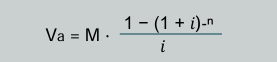

ya que las cuotas pendientes del sistema francés son constantes. Esta fórmula se obtiene descontando cada cuota futura mediante descuento racional compuesto y sumando todos los valores presentes.

In [41]:
# ALEMÁN: renta geométrica
al = datos_final["metodo"] == "aleman"

C = datos_final.loc[al, "capital_prestado"]
i = datos_final.loc[al, "interes_anual"] / 100 / 12
n = datos_final.loc[al, "num_meses"].astype(int)

A = C / n                          # amortización constante
N = n - n // 2                     # cuotas pendientes
M1 = A + (C - (n // 2) * A) * i    # primera cuota pendiente
q = (A * (1 + i) / M1) ** (1 / (N - 1))   # razón: de la primera a la última cuota

datos_final.loc[al, "VP_cuotas_pendientes"] = M1 * (1 - (q / (1 + i)) ** N) / (1 + i - q)

Las cuotas pendientes no son constantes: bajan cada mes (rentas en progresión geométrica)

- $A = C/n$: amortización constante.
- $N = n - n//2$: cuotas que quedan por pagar.
- Primera cuota pendiente: cuota = amortización + intereses, con intereses = capital pendiente × $i$, y capital pendiente tras $n//2$ pagos = $C - (n//2)\cdot A$. Por tanto: $M_1 = A + \big(C - (n//2)\cdot A\big)\cdot i$.
- Última cuota: antes del último pago el capital pendiente es $A$, así que la última cuota es $A + A\cdot i = A(1+i)$.
- Razón $q$: en una renta geométrica cada término es el anterior multiplicado por $q$, así que el último es $M_1\cdot q^{N-1}$. Igualando a $A(1+i)$ y despejando: $q = \left(\dfrac{A(1+i)}{M_1}\right)^{1/(N-1)}$. Como $M_1 > A(1+i)$, resulta $q<1$ (renta decreciente) y por tanto $q \neq 1+i$.

Con $q \neq 1+i$, el valor actual de la renta es:

$$V_a = M_1 \cdot \frac{1 - q^{N}(1+i)^{-N}}{1+i-q}$$

In [ ]:
#Validar con el cuadro de amortización (el primer préstamo de cada método)
for metodo, cuadro_fn in [("frances", cuadro_frances), ("aleman", cuadro_aleman)]:
    p = datos_final[datos_final["metodo"] == metodo].iloc[0]
    cuadro = cuadro_fn(p["capital_prestado"], p["interes_anual"], int(p["num_meses"]))
    mitad = int(p["num_meses"]) // 2
    saldo = cuadro.loc[cuadro["mes"] == mitad, "saldo_final"].iloc[0]
    print(metodo, "| VP:", round(p["VP_cuotas_pendientes"], 2), "| saldo del cuadro:", round(saldo, 2))

frances | VP: 20969.31 | saldo del cuadro: 20969.31
aleman | VP: 3471.5 | saldo del cuadro: 3486.5


 coge el primer préstamo francés y el primer alemán y construye un cuadro de amortización mes a mes. Mira cuánto deuda queda en el mes de la mitad (saldo del cuadro) y lo compara con el VP. 
 
 En el francés --> VP y saldo coinciden, 20.969,31 €. 
 
 En el alemán--> VP de 3.471,50 € frente a un saldo del cuadro de 3.486,50 €. La diferencia es de 15,00 €. Es normal que no coincidan, porque la renta geométrica es una aproximación de las cuotas alemanas, que decrecen de forma lineal.

In [43]:
#. Resumen por método
datos_final["VP_sobre_capital"] = datos_final["VP_cuotas_pendientes"] / datos_final["capital_prestado"]
print(datos_final.groupby("metodo")[["VP_cuotas_pendientes", "VP_sobre_capital"]].mean().round(3))
print("VP total de la cartera (€):", round(datos_final["VP_cuotas_pendientes"].sum(), 2))

         VP_cuotas_pendientes  VP_sobre_capital
metodo                                         
aleman               8739.859             0.499
frances             35547.330             0.538
VP total de la cartera (€): 1834140715.84


#Resultados
 Se ha calculado el valor presente de las cuotas pendientes a mitad de plazo (mes n // 2) de cada préstamo con el método que se le asignó en el Objetivo 1.

- Préstamos franceses: las cuotas pendientes son constantes, así que se valoran como una renta constante pospagable, descontadas al tipo mensual del préstamo. El resultado coincide con el saldo del cuadro de amortización (ej.: préstamo IYOL1S, 20.969,31 €).
- Préstamos alemanes: las cuotas pendientes decrecen, y se valoran como una renta en progresión geométrica (primer término M1, razón q < 1, tipo mensual). El resultado se aproxima al saldo del cuadro (ej.: préstamo O77MPJ, 3.471,50 € frente a 3.486,50 €).
- En media, el valor presente representa un 53,8 % del capital en el francés y un 49,9 % en el alemán. El valor presente total de la cartera es de 1.834.140.715,84 €.